# High-rate stairway codes — logical error rate vs p

Curves of logical error rate vs physical error rate `p` for each `[[n,k,d]]` stairway code in the
`threshold_stairway` collection (decoded with the Tesseract decoder)."""

In [1]:
import sys
import datetime
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt

# Shared backend (also used by tools/plot_high_rate.py) so the notebook and the
# CLI produce identical figures.
from high_rate_analysis import (
    load_collection,
    plot_panel,
    add_pbz_axis,
    set_paper_style,
)

%load_ext autoreload
%autoreload 2

In [ ]:
CSV_GLOB = '../out/collection/threshold_stairway_debug,*.csv'
BIAS = 1

# Load + merge + resolve [[n,k,d]] codes at the chosen Z-bias (see
# high_rate_analysis.load_collection).
df, code_order = load_collection(CSV_GLOB, BIAS)

n_zero = int((df['errors'] == 0).sum())
print(f'{len(df)} rows; bias={BIAS:g}; codes={code_order}')
print(f'zero-error rows kept: {n_zero}/{len(df)} (sinter draws them as upper bounds)')
print(f'low-confidence shots: {int(df["low_confidence_shots"].sum())} / {int(df["shots"].sum())} total')
df.head()

24 rows; bias=10; codes=['[[192,16,4]]', '[[192,6,9]]', '[[288,14,10]]']
zero-error rows kept: 7/24 (sinter draws them as upper bounds)
low-confidence shots: 1306 / 1172596 total


,strong_id,shots,errors,discards,seconds,low_confidence_shots,decoder,json_metadata,p,p_bell_z,bias,n,k,d,code,pL,pL_err
0,03a2f539faef6a9000234556da484601c860733e9f31c0...,70000,0,0,6090.071255,0,tesseract_short,"{'p': 0.0001, 'rounds': -1, 'noise_model': 'bi...",0.000100,0.001000,10.0,288,14,10,"[[288,14,10]]",0.000000,0.000000
1,07d26e80790b46a0581da01a7716be6db16a2afa9b202e...,1897,755,0,15400.576878,0,tesseract_short,"{'p': 0.0008576958985908946, 'rounds': -1, 'no...",0.000858,0.008577,10.0,192,16,4,"[[192,16,4]]",0.397997,0.011238
2,0c3b5a0bdc1e2def227b041dd21bee21df609f81a7d6c0...,70000,0,0,1401.643047,0,tesseract_short,"{'p': 0.00013593563908785255, 'rounds': -1, 'n...",0.000136,0.001359,10.0,192,16,4,"[[192,16,4]]",0.000000,0.000000
3,1aa064dd167b498dfcb2e10fb0e3bedcdb54846739f7cf...,70000,0,0,19392.968153,0,tesseract_short,"{'p': 0.00018478497974222906, 'rounds': -1, 'n...",0.000185,0.001848,10.0,288,14,10,"[[288,14,10]]",0.000000,0.000000
4,22bd889e4e916656cedbd809dcc588f1191be40c8a6bec...,70000,81,0,11576.356251,0,tesseract_short,"{'p': 0.0003414548873833601, 'rounds': -1, 'no...",0.000341,0.003415,10.0,192,16,4,"[[192,16,4]]",0.001157,0.000128


Saved ../out/figures/20260715_high_rate_stairway_bias10.pdf


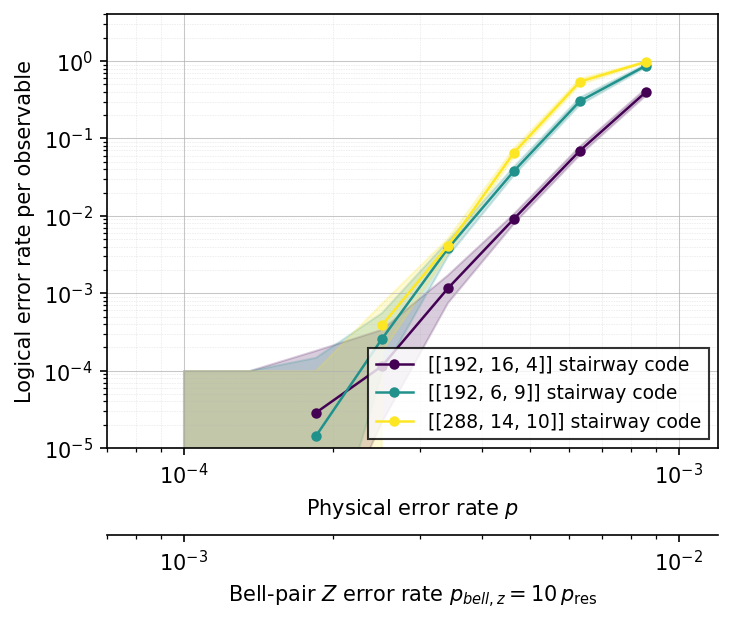

In [3]:
# Single stairway panel. Unlike the two-panel high_rate.ipynb figure (which
# rescales stairway curves by d/16), this standalone view counts a per-
# observable failure (unit 1). plot_panel / add_pbz_axis are shared with
# tools/plot_high_rate.py.
set_paper_style()

fig, ax = plt.subplots(1, 1, figsize=(5, 4))
plot_panel(ax, df, code_order, label_suffix='stairway code',
           failure_units_per_shot_func=lambda s: 1)

ax.set_xlim(float(df['p'].min()) * 0.7, float(df['p'].max()) * 1.4)
# Override plot_panel's default "residual error rate" label for this figure.
ax.set_xlabel(r'Physical error rate $p$')

fig.tight_layout()
fig.subplots_adjust(bottom=0.24)
add_pbz_axis(ax, BIAS)
fig.set_dpi(150)

out_dir = Path('../out/figures')
out_dir.mkdir(parents=True, exist_ok=True)
date = datetime.date.today().strftime('%Y%m%d')
out_path = out_dir / f'{date}_high_rate_stairway_bias{int(BIAS)}.pdf'
fig.savefig(out_path, bbox_inches='tight')
print(f'Saved {out_path}')
plt.show()